In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline


In [2]:
# PDF exploration notebook
#
# Kernel: lemma_extractor/.venv/bin/python
#
# Page numbering
# ----------------
# HTML/PDF filenames use a 4-digit scan index (e.g. ..._0007.html).
# The TOC <page number="N"> is the printed book page; usually N == scan index.
# If PDF and HTML drift, tune PDF_OFFSET below (pdf_file = html_file + offset).

from __future__ import annotations

import re
import tarfile
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import pdfplumber

NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "lemma_extractor" else NOTEBOOK_DIR
PDF_TAR = PROJECT_ROOT / "pdf_sourcs" / "schuttepdfs.tar.gz"
PDF_CACHE = PROJECT_ROOT / "pdf_sourcs" / "cache"
NL_HTML_DIR = PROJECT_ROOT / "schutte_binnenland"
BL_HTML_DIR = PROJECT_ROOT / "schutte_buitenland"
TOC_NL = PROJECT_ROOT / "toc_nl.xml"
TOC_BL = PROJECT_ROOT / "toc_bl.xml"

CORPUS_PATTERNS = {
    "nl": {
        "pdf_tar_prefix": "schutte/2/originelen/pdf/schutte_nederlandsevertegenwoordigersinbuitenland_{page:04d}.pdf",
        "html_glob": "schutte_nederlandsevertegenwoordigersinbuitenland_{page:04d}.html",
        "toc": TOC_NL,
    },
    "bl": {
        "pdf_tar_prefix": "schutte/1/originelen/pdf/schutte_buitenlandsevertegenwoordigersinnederland_{page:04d}.pdf",
        "html_glob": "schutte_buitenlandsevertegenwoordigersinnederland_{page:04d}.html",
        "toc": TOC_BL,
    },
}

# pdf scan index = html scan index + offset  (per corpus)
PDF_OFFSET = {"nl": 0, "bl": 0}

PDF_CACHE.mkdir(parents=True, exist_ok=True)
print(f"Project root : {PROJECT_ROOT}")
print(f"PDF archive  : {PDF_TAR} ({'found' if PDF_TAR.exists() else 'MISSING'})")
print(f"PDF offset   : NL {PDF_OFFSET['nl']:+d}, BL {PDF_OFFSET['bl']:+d}")

Project root : /Users/rikhoekstra/Nextcloud2/Republic/gekoppelde_resources/schutte-bewerkingen
PDF archive  : /Users/rikhoekstra/Nextcloud2/Republic/gekoppelde_resources/schutte-bewerkingen/pdf_sourcs/schuttepdfs.tar.gz (found)
PDF offset   : NL +0, BL +0


In [3]:
def load_toc(corpus: str) -> dict[int, dict]:
    """schutte_nr -> {title, book_page, toc_source}."""
    root = ET.parse(CORPUS_PATTERNS[corpus]["toc"]).getroot()
    out: dict[int, dict] = {}
    for item in root.iter("item"):
        sn = item.get("schutte_nr")
        if not sn:
            continue
        page_el = item.find("page")
        title_el = item.find("title")
        out[int(sn)] = {
            "title": (title_el.text or "").strip() if title_el is not None else "",
            "book_page": int(page_el.get("number", "0")) if page_el is not None else 0,
            "toc_source": int(page_el.get("source", "0")) if page_el is not None else 0,
        }
    return out


def resolve_pages(
    corpus: str,
    *,
    schutte_nr: int | None = None,
    book_page: int | None = None,
    html_file: int | None = None,
) -> dict:
    """Map lemma / book page / html file -> html_file, pdf_file, metadata.

    html_file defaults to book_page (printed page == scan index in most cases).
    pdf_file = html_file + PDF_OFFSET[corpus].
    """
    toc = load_toc(corpus)
    meta = None

    if schutte_nr is not None:
        meta = toc.get(schutte_nr)
        if meta is None:
            raise KeyError(f"schutte_nr {schutte_nr} not in {corpus} TOC")
        book_page = meta["book_page"]

    if html_file is None:
        if book_page is None:
            raise ValueError("provide schutte_nr, book_page, or html_file")
        html_file = book_page

    pdf_file = html_file + PDF_OFFSET[corpus]
    return {
        "corpus": corpus,
        "schutte_nr": schutte_nr,
        "book_page": book_page,
        "html_file": html_file,
        "pdf_file": pdf_file,
        "pdf_offset": PDF_OFFSET[corpus],
        "title": meta["title"] if meta else None,
        "toc_source": meta["toc_source"] if meta else None,
    }


def pdf_path(corpus: str, pdf_file: int) -> Path:
    """Return local PDF path, extracting from tar on first use."""
    if corpus not in CORPUS_PATTERNS:
        raise ValueError(f"corpus must be one of {list(CORPUS_PATTERNS)}")

    member = CORPUS_PATTERNS[corpus]["pdf_tar_prefix"].format(page=pdf_file)
    cached = PDF_CACHE / Path(member).name

    if cached.exists():
        return cached

    if not PDF_TAR.exists():
        raise FileNotFoundError(f"PDF archive not found: {PDF_TAR}")

    with tarfile.open(PDF_TAR, "r:gz") as tar:
        try:
            tar.extract(member, path=PDF_CACHE, filter="data")
        except KeyError:
            raise FileNotFoundError(f"{member} not in archive") from None

    extracted = PDF_CACHE / member
    if extracted.exists() and extracted != cached:
        extracted.rename(cached)
        for parent in [extracted.parent, extracted.parent.parent, extracted.parent.parent.parent]:
            if parent != PDF_CACHE and parent.exists() and not any(parent.iterdir()):
                parent.rmdir()

    return cached


def html_path(corpus: str, html_file: int) -> Path | None:
    html_dir = NL_HTML_DIR if corpus == "nl" else BL_HTML_DIR
    path = html_dir / CORPUS_PATTERNS[corpus]["html_glob"].format(page=html_file)
    return path if path.exists() else None


def open_pdf_page(corpus: str, pdf_file: int):
    return pdfplumber.open(pdf_path(corpus, pdf_file))


# --- pick what to explore (set exactly one selector) ---
CORPUS = "nl"          # "nl" or "bl"
SCHUTTE_NR = 6         # lemma number from TOC (preferred)
BOOK_PAGE = None       # or printed book page directly
HTML_FILE = None       # or html scan index directly

pages = resolve_pages(CORPUS, schutte_nr=SCHUTTE_NR, book_page=BOOK_PAGE, html_file=HTML_FILE)
HTML_FILE = pages["html_file"]
PDF_FILE = pages["pdf_file"]

print("Resolved pages:")
for k, v in pages.items():
    print(f"  {k:12} {v}")
print(f"\nHTML exists: {html_path(CORPUS, HTML_FILE)}")
print(f"PDF path   : {pdf_path(CORPUS, PDF_FILE)}")

Resolved pages:
  corpus       nl
  schutte_nr   6
  book_page    7
  html_file    7
  pdf_file     7
  pdf_offset   0
  title        6. Mijle, Cornelis van der
  toc_source   2

HTML exists: /Users/rikhoekstra/Nextcloud2/Republic/gekoppelde_resources/schutte-bewerkingen/schutte_binnenland/schutte_nederlandsevertegenwoordigersinbuitenland_0007.html
PDF path   : /Users/rikhoekstra/Nextcloud2/Republic/gekoppelde_resources/schutte-bewerkingen/pdf_sourcs/cache/schutte_nederlandsevertegenwoordigersinbuitenland_0007.pdf


In [4]:
# Sync check: compare printed page number on PDF vs HTML vs TOC
with open_pdf_page(CORPUS, PDF_FILE) as pdf:
  pdf_page_num = pdf.pages[0].extract_text().split()[0] if pdf.pages[0].extract_text() else "?"

html = html_path(CORPUS, HTML_FILE)
html_page_num = None
if html:
    first = re.split(r"<br\s*/?>", html.read_bytes().decode("latin-1"), flags=re.I)[0].strip()
    html_page_num = first if re.fullmatch(r"\d+", first) else first[:20]

print(f"TOC book page     : {pages.get('book_page')}")
print(f"HTML file         : ..._{HTML_FILE:04d}.html  (leading token: {html_page_num!r})")
print(f"PDF file          : ..._{PDF_FILE:04d}.pdf   (offset {PDF_OFFSET[CORPUS]:+d})")
print(f"PDF leading token : {pdf_page_num!r}")
if pages.get("book_page") and str(pages["book_page"]) not in (str(pdf_page_num), str(html_page_num)):
    print("⚠ page numbers differ — try adjusting PDF_OFFSET")
else:
    print("✓ page numbers align at file start")

TOC book page     : 7
HTML file         : ..._0007.html  (leading token: '7')
PDF file          : ..._0007.pdf   (offset +0)
PDF leading token : '7'
✓ page numbers align at file start


In [5]:
with open_pdf_page(CORPUS, PDF_FILE) as pdf:
    page = pdf.pages[0]
    fonts = sorted({c["fontname"] for c in page.chars})
    print("Fonts on page:", fonts)
    print()
    print("Plain text (first 800 chars):")
    print(page.extract_text()[:800])

Fonts on page: ['Helvetica-Bold', 'Times-Bold', 'Times-BoldItalic', 'Times-Italic', 'Times-Roman']

Plain text (first 800 chars):
7
van der Wolff, die bij res. 16 okt. 1629/500 toegelegd kreeg, en
Mr. Cornells de Montigny de Glarges, ridder van St. Michiel,
heer van Eslemmes, zie onder de consuls te Calais.
Johan van Woestinghoven komt als zijn dienaar, later zijn secre
taris voor tussen 29 april 1606 en 13 aug. 1609; deze reisde in
1606, 1607 en 1609 naar 's-Gravenhage.
Zijn secretaris tijdens zijn missie naar Venetië in 1620 en Enge
land 1621 tot 1623 was Mr. Constantijn Huygens, (Engels) ridder
(okt. 1622), ridder van St. Michiel (1632), heer van Zuylichem,
Zeelhem en Monnikenland, geb. 's-Gravenhage 4 sept. 1596,
juridisch student te Leiden 20 mei 1616, disputeerde aldaar in
aug. 1617, reisde naar Engeland, secretaris te Venetië 1620 en
Engeland 1621 tot 1623, reisde opnieuw naar Engeland in jan.
(?) 1624, secret


In [6]:
def words_dataframe(corpus: str, pdf_file: int) -> pd.DataFrame:
    with open_pdf_page(corpus, pdf_file) as pdf:
        page = pdf.pages[0]
        words = page.extract_words(extra_attrs=["fontname", "size"])
    return pd.DataFrame(words)


df = words_dataframe(CORPUS, PDF_FILE)
df.head(12)

,text,x0,x1,top,doctop,bottom,upright,height,width,direction,fontname,size
0,7,341.700000,347.20440,43.97,43.97,53.97,True,10.0,5.504400,ltr,Helvetica-Bold,10.0
1,van,79.800000,94.09560,67.17,67.17,77.17,True,10.0,14.295600,ltr,Times-Italic,10.0
2,der,95.999370,109.19607,67.17,67.17,77.17,True,10.0,13.196700,ltr,Times-Italic,10.0
3,"Wolff,",113.399071,139.74413,67.17,67.17,77.17,True,10.0,26.345058,ltr,Times-Italic,10.0
4,die,143.643740,155.66531,67.17,67.17,77.17,True,10.0,12.021570,ltr,Times-Roman,10.0
5,bij,159.020420,169.25702,67.17,67.17,77.17,True,10.0,10.236600,ltr,Times-Roman,10.0
6,res.,173.037830,187.13543,67.17,67.17,77.17,True,10.0,14.097600,ltr,Times-Roman,10.0
7,16,191.298380,201.19838,67.17,67.17,77.17,True,10.0,9.900000,ltr,Times-Roman,10.0
8,okt.,203.897120,219.52130,67.17,67.17,77.17,True,10.0,15.624180,ltr,Times-Roman,10.0
9,1629/500,224.048570,264.85439,67.17,67.17,77.17,True,10.0,40.805820,ltr,Times-Roman,10.0


In [7]:
def group_lines(words: pd.DataFrame, y_tol: float = 2.0) -> list[dict]:
    """Group words into lines using their vertical position (top)."""
    if words.empty:
        return []

    sorted_words = words.sort_values(["top", "x0"])
    lines: list[dict] = []
    current_top = None
    bucket: list[dict] = []

    for row in sorted_words.itertuples(index=False):
        row_dict = row._asdict()
        if current_top is None or abs(row_dict["top"] - current_top) > y_tol:
            if bucket:
                lines.append(_line_from_words(bucket))
            bucket = [row_dict]
            current_top = row_dict["top"]
        else:
            bucket.append(row_dict)

    if bucket:
        lines.append(_line_from_words(bucket))

    return lines


def _line_from_words(words: list[dict]) -> dict:
    words = sorted(words, key=lambda w: w["x0"])
    x0 = words[0]["x0"]
    text = " ".join(w["text"] for w in words)
    fonts = Counter(w["fontname"] for w in words)
    return {
        "top": round(words[0]["top"], 1),
        "x0": round(x0, 1),
        "text": text,
        "fonts": dict(fonts),
        "italic_bits": [w["text"] for w in words if "Italic" in w["fontname"]],
    }


lines = group_lines(df)
for ln in lines[:25]:
    italic = f"  italic={ln['italic_bits']}" if ln["italic_bits"] else ""
    print(f"x={ln['x0']:6.1f}  {ln['text'][:100]}{italic}")

x= 341.7  7
x=  79.8  van der Wolff, die bij res. 16 okt. 1629/500 toegelegd kreeg, en  italic=['van', 'der', 'Wolff,']
x=  79.5  Mr. Cornells de Montigny de Glarges, ridder van St. Michiel,  italic=['Cornells', 'de', 'Montigny', 'de', 'Glarges,']
x=  79.5  heer van Eslemmes, zie onder de consuls te Calais.
x=  79.2  Johan van Woestinghoven komt als zijn dienaar, later zijn secre  italic=['Johan', 'van', 'Woestinghoven']
x=  79.2  taris voor tussen 29 april 1606 en 13 aug. 1609; deze reisde in
x=  80.1  1606, 1607 en 1609 naar 's-Gravenhage.
x=  79.5  Zijn secretaris tijdens zijn missie naar Venetië in 1620 en Enge
x=  78.9  land 1621 tot 1623 was Mr. Constantijn Huygens, (Engels) ridder  italic=['Constantijn', 'Huygens,']
x=  78.9  (okt. 1622), ridder van St. Michiel (1632), heer van Zuylichem,
x=  78.9  Zeelhem en Monnikenland, geb. 's-Gravenhage 4 sept. 1596,
x=  77.7  juridisch student te Leiden 20 mei 1616, disputeerde aldaar in
x=  79.5  aug. 1617, reisde naar Engeland, secretari

In [8]:
# Footnote marker candidates: short italic digit runs attached to body text
italic_words = df[df["fontname"].str.contains("Italic", na=False)]
print(f"Italic words on page: {len(italic_words)}")
print(italic_words[["text", "x0", "top", "fontname"]].head(20).to_string(index=False))

# Pure digit italic tokens are likely superscript footnote numbers
fn_candidates = italic_words[italic_words["text"].str.fullmatch(r"\d+[a-z]?")]
print(f"\nItalic digit tokens: {len(fn_candidates)}")
print(fn_candidates[["text", "x0", "top"]].to_string(index=False))

Italic words on page: 44
         text         x0     top         fontname
          van  79.800000  67.170     Times-Italic
          der  95.999370  67.170     Times-Italic
       Wolff, 113.399071  67.170     Times-Italic
     Cornells  99.896970  78.570     Times-Italic
           de 137.396190  78.570     Times-Italic
     Montigny 150.895830  78.570     Times-Italic
           de 194.995380  78.570     Times-Italic
     Glarges, 208.794990  78.570     Times-Italic
        Johan  79.200000 101.370     Times-Italic
          van 106.799220 101.370     Times-Italic
Woestinghoven 124.798410 101.370     Times-Italic
  Constantijn 195.159660 148.470     Times-Italic
     Huygens, 243.759750 148.470     Times-Italic
     Frederik  78.900000 228.270     Times-Italic
     Hendrik, 116.400210 228.270     Times-Italic
       Willem 156.900120 228.270     Times-Italic
           II 188.099970 228.270 Times-BoldItalic
       Willem 211.844130 228.270     Times-Italic
         III, 243.043980 

In [9]:
# Compare PDF vs HTML for the paired files (html_file vs pdf_file)
html = html_path(CORPUS, HTML_FILE)
if html is None:
    print(f"No HTML file in repo for ..._{HTML_FILE:04d}.html")
else:
    raw = html.read_bytes().decode("latin-1")
    html_lines = [ln.strip() for ln in re.split(r"<br\s*/?>", raw, flags=re.I) if ln.strip()]

    print(f"HTML ..._{HTML_FILE:04d}.html  ({len(html_lines)} lines)")
    print(f"PDF  ..._{PDF_FILE:04d}.pdf   ({len(lines)} lines, offset {PDF_OFFSET[CORPUS]:+d})")
    print()
    print("--- HTML line 0 ---")
    print(html_lines[0][:200])
    print("--- PDF line 0 ---")
    print(lines[0]["text"][:200] if lines else "(empty)")

HTML ..._0007.html  (44 lines)
PDF  ..._0007.pdf   (44 lines, offset +0)

--- HTML line 0 ---
7
--- PDF line 0 ---
7


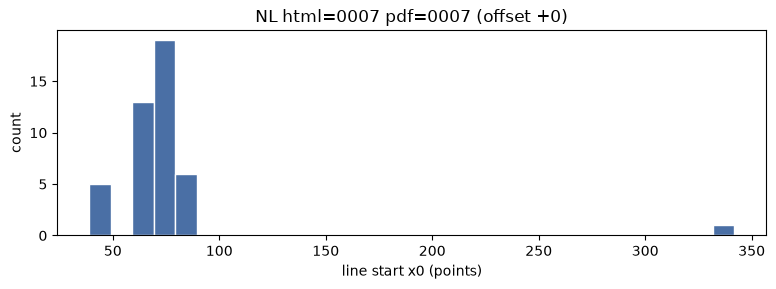

Most common line-start x0 values:
78.9     13
63.6      8
79.5      4
79.2      3
78.6      2
39.3      2
341.7     1
79.8      1
Name: count, dtype: int64


In [10]:
# Indentation clusters: x0 of line starts (proxy for leading spaces in HTML)
line_starts = pd.Series([ln["x0"] for ln in lines])
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(line_starts, bins=30, color="#4a6fa5", edgecolor="white")
ax.set_xlabel("line start x0 (points)")
ax.set_ylabel("count")
ax.set_title(f"{CORPUS.upper()} html={HTML_FILE:04d} pdf={PDF_FILE:04d} (offset {PDF_OFFSET[CORPUS]:+d})")
plt.tight_layout()
plt.show()

print("Most common line-start x0 values:")
print(line_starts.value_counts().head(8))

## Side-by-side preview

Next cell builds `preview/side_by_side.html`: PDF + HTML source + **current** vs **proposed** header/body for sample lemmas.

In [12]:
import html as html_lib
import json
from IPython.display import HTML, display

LEMMAS_DIR = PROJECT_ROOT / "lemmas"
SITE_DIR = NOTEBOOK_DIR / "_site"
PREVIEW_DIR = NOTEBOOK_DIR / "preview"
EXCEL = {
    "nl": PROJECT_ROOT / "dijkstra_bew" / "schutte_binnenland_met_lemma.xlsx",
    "bl": PROJECT_ROOT / "dijkstra_bew" / "schutte_buitenland_met_lemma.xlsx",
}

# Pick a few lemmas to compare (corpus, schutte_nr)
SAMPLES = [
    ("nl", 6),   # entry line sometimes misclassified as footnote
    ("nl", 13),  # typical long entry line
    ("nl", 34),
    ("bl", 5),
    ("bl", 10),
]

ENTRY_RE = re.compile(r"^(\d+)\.\s+")


def _display_name(row: dict) -> str:
    parts = [row.get("name", ""), row.get("givenname", "")]
    intra = row.get("Intraposition") or row.get("intraposition")
    if intra:
        parts.append(str(intra))
    post = row.get("Postposition") or row.get("postposition")
    if post:
        parts.append(str(post))
    # surname, givenname van …
    name = parts[0] or "?"
    given = parts[1] or ""
    rest = " ".join(str(p) for p in parts[2:] if p)
    if given:
        return f"{name}, {given}" + (f" {rest}" if rest else "")
    return name


import sys
sys.path.insert(0, str(NOTEBOOK_DIR / "src"))
from lemma_extractor.read_excel import parse_schutte_nr

def load_excel_meta(corpus: str) -> dict:
    """Load Dijkstra Excel; schutte_nr may be int or str (e.g. 418a)."""
    df = pd.read_excel(EXCEL[corpus])
    out = {}
    for _, row in df.iterrows():
        nr = parse_schutte_nr(row.get("schutte_nr"))
        if nr is None:
            continue
        out[nr] = {k: (None if pd.isna(v) else v) for k, v in row.items()}
    return out


def lemma_xml_lines(corpus: str, nr: int) -> list[str]:
    p = LEMMAS_DIR / corpus / f"{corpus}_{nr:04d}.xml"
    if not p.exists():
        return []
    root = ET.parse(p).getroot()
    return [(el.text or "").strip() for el in root.findall("line") if el.get("type") != "paginahoofd"]


def html_lines_around_entry(corpus: str, html_file: int, nr: int, context: int = 4) -> list[str]:
    path = html_path(corpus, html_file)
    if path is None:
        return []
    raw = path.read_bytes().decode("latin-1")
    lines = [ln.strip() for ln in re.split(r"<br\s*/?>", raw, flags=re.I) if ln.strip()]
    for i, ln in enumerate(lines):
        m = ENTRY_RE.match(ln)
        if m and int(m.group(1)) == nr:
            start = max(0, i - 1)
            return lines[start : i + context]
    return lines[: context + 2]


def pdf_entry_line(corpus: str, pdf_file: int, nr: int) -> str | None:
    with open_pdf_page(corpus, pdf_file) as pdf:
        words = pdf.pages[0].extract_words()
    from collections import defaultdict
    buckets = defaultdict(list)
    for w in words:
        buckets[round(w["top"], 0)].append(w)
    pat = re.compile(rf"^{nr}\.\s")
    for top in sorted(buckets):
        text = " ".join(w["text"] for w in sorted(buckets[top], key=lambda x: x["x0"]))
        if pat.match(text):
            return text
    return None


def site_first_body(corpus: str, nr: int) -> str:
    p = SITE_DIR / corpus / f"{nr:04d}" / "index.html"
    if not p.exists():
        return "(site not built — run build.py)"
    text = p.read_text(encoding="utf-8")
    m = re.search(r'<div class="lemma-body">.*?<p class="zone-[^"]+">(.*?)</p>', text, re.S)
    return re.sub(r"<[^>]+>", "", m.group(1)) if m else "(no body found)"


def period_label(meta: dict, toc_title: str) -> str:
    b, e = meta.get("schutte_beginjaar"), meta.get("schutte_eindjaar")
    functie = meta.get("schutte_functie") or ""
    if b or e:
        bi = int(b) if b else "?"
        ei = int(e) if e else "?"
        return f"{bi}–{ei} {functie}".strip()
    return functie or toc_title


def render_header_current(name: str, nr: int, period: str, functie: str, chapter: str, page: int) -> str:
    return f"""
    <div class="panel current">
      <h4>Huidige site</h4>
      <h2>{html_lib.escape(name)}</h2>
      <div class="meta">
        <span>Nr. {nr}</span>
        <span>{html_lib.escape(period)}</span>
        <span>{html_lib.escape(functie or '')}</span>
        <span>{html_lib.escape(chapter)}</span>
        <span>Pag. {page}</span>
      </div>
    </div>"""


def render_header_proposed(name: str, nr: int, functie: str, chapter: str) -> str:
    return f"""
    <div class="panel proposed">
      <h4>Voorstel</h4>
      <h2>{html_lib.escape(name)}</h2>
      <div class="meta">
        <span><strong>Schutte nr.</strong> {nr}</span>
        <span>{html_lib.escape(functie or '')}</span>
        <span>{html_lib.escape(chapter)}</span>
      </div>
    </div>"""


excel = {"nl": load_excel_meta("nl"), "bl": load_excel_meta("bl")}
toc = {"nl": load_toc("nl"), "bl": load_toc("bl")}
blocks: list[str] = []

for corpus, nr in SAMPLES:
    pages = resolve_pages(corpus, schutte_nr=nr)
    meta = excel[corpus].get(nr, {})
    toc_meta = toc[corpus][nr]
    name = _display_name(meta) if meta else re.sub(r"^\d+\.\s+", "", toc_meta["title"])
    functie = str(meta.get("schutte_functie") or "")
    period = period_label(meta, toc_meta["title"])
    xml_lines = lemma_xml_lines(corpus, nr)
    entry = xml_lines[0] if xml_lines else pdf_entry_line(corpus, pages["pdf_file"], nr) or "(geen entryregel)"
    body_rest = " ".join(xml_lines[:3]) if xml_lines else site_first_body(corpus, nr)
    html_snip = html_lines_around_entry(corpus, pages["html_file"], nr)
    pdf_uri = pdf_path(corpus, pages["pdf_file"]).resolve().as_uri()

    blocks.append(f"""
    <section class="sample">
      <h3>{corpus.upper()} #{nr} — {html_lib.escape(name)} <small>(html {pages['html_file']:04d} · pdf {pages['pdf_file']:04d})</small></h3>
      <div class="row headers">
        {render_header_current(name, nr, period, functie, toc_meta['title'].split('.')[-1].strip() if '.' in toc_meta['title'] else '', pages['book_page'])}
        {render_header_proposed(name, nr, functie, toc_meta['title'].split('.')[-1].strip() if '.' in toc_meta['title'] else '')}
      </div>
      <div class="row body-compare">
        <div class="panel"><h4>Body nu (1e alinea)</h4><p class="body">{html_lib.escape(site_first_body(corpus, nr)[:600])}</p></div>
        <div class="panel"><h4>Body voorstel (entry + vervolg)</h4><p class="body entry">{html_lib.escape(entry[:300])}</p><p class="body">{html_lib.escape(' '.join(xml_lines[1:3])[:400])}</p></div>
      </div>
      <div class="row sources">
        <div class="panel pdf"><h4>PDF</h4><iframe src="{pdf_uri}" title="pdf"></iframe></div>
        <div class="panel"><h4>HTML bron (rond entry)</h4><pre>{html_lib.escape(chr(10).join(html_snip))}</pre></div>
      </div>
    </section>""")

css = """
body { font-family: Georgia, serif; margin: 1.5rem; background: #f6f4ef; color: #222; }
.sample { background: #fff; border: 1px solid #ddd; border-radius: 8px; padding: 1rem; margin-bottom: 2rem; }
.row { display: grid; gap: 1rem; margin-top: 1rem; }
.headers { grid-template-columns: 1fr 1fr; }
.body-compare { grid-template-columns: 1fr 1fr; }
.sources { grid-template-columns: 1fr 1fr; }
.panel { border: 1px solid #e0ddd6; border-radius: 6px; padding: 0.75rem; background: #faf9f6; }
.panel h4 { margin: 0 0 0.5rem; font-size: 0.8rem; text-transform: uppercase; color: #666; }
.panel h2 { margin: 0.2rem 0; font-size: 1.4rem; }
.meta span { display: inline-block; margin-right: 0.75rem; font-size: 0.85rem; color: #444; }
.proposed { border-color: #4a6fa5; background: #f0f4fa; }
.current { border-color: #ccc; }
.body { font-size: 0.95rem; line-height: 1.5; }
.body.entry { font-weight: 600; margin-bottom: 0.5rem; }
pre { white-space: pre-wrap; font-size: 0.8rem; max-height: 280px; overflow: auto; }
iframe { width: 100%; height: 420px; border: 1px solid #ccc; }
"""

out_html = f"""<!DOCTYPE html><html lang="nl"><head><meta charset="utf-8">
<title>Schutte side-by-side preview</title><style>{css}</style></head>
<body><h1>Side-by-side: huidige site vs voorstel header</h1>
<p>Naam en functie uit spreadsheet; entry-regel blijft in de lemma-tekst.</p>
{''.join(blocks)}</body></html>"""

PREVIEW_DIR.mkdir(exist_ok=True)
out_path = PREVIEW_DIR / "side_by_side.html"
out_path.write_text(out_html, encoding="utf-8")
print(f"Wrote {out_path}")
print(f"Open: file://{out_path.resolve()}")
display(HTML(f'<p><a href="{out_path.resolve().as_uri()}" target="_blank">Open preview in browser</a></p>'))

Wrote /Users/rikhoekstra/Nextcloud2/Republic/gekoppelde_resources/schutte-bewerkingen/lemma_extractor/preview/side_by_side.html
Open: file:///Users/rikhoekstra/Nextcloud2/Republic/gekoppelde_resources/schutte-bewerkingen/lemma_extractor/preview/side_by_side.html
